# 📊 NLP Project for Disaster Tweet Classification

#### **File:** Project7.ipynb
#### **Developer:** Sukanya Naik 👩‍💻
#### **Dataset Name:** twitter_disaster.csv
#### **Description:** In today's digital age, social media platforms like Twitter play a crucial role in disseminating information, especially during emergencies and disasters. However, distinguishing between tweets that genuinely indicate a disaster and those that do not can be challenging, even for humans. The challenge is to build a machine learning model capable of accurately classifying tweets as either related to real disasters or not. Thus, the model needs to discern the true intent behind the language used in tweets, which can be nuanced and context-dependent.


## Import Libraries

🔢 NumPy : Symbolizes numerical operations, multidimensional arrays, and mathematical foundations.

🐼 Pandas : Matches the library’s logo and represents powerful data manipulation and analysis.

📊 Matplotlib : Represents plotting, graphs, and general data visualization.

🌊 Seaborn : Symbolizes advanced statistical visualizations, heatmaps, and aesthetically pleasing plots.

📊 Plotly is a powerful open‑source Python library for creating interactive, publication‑quality visualizations. Unlike static libraries such as Matplotlib or Seaborn, Plotly charts let you hover, zoom, pan, and toggle data series directly in the browser or notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt

##Part 1: Data Exploration and Preparation

In [2]:
nlp_data = pd.read_excel("twitter_disaster.xlsx")

In [3]:
nlp_data.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [4]:
nlp_data.tail()

,id,keyword,location,text,target
7608,10869,NaN,NaN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NaN,NaN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NaN,NaN,Police investigating after an e-bike collided ...,1
7612,10873,NaN,NaN,The Latest: More Homes Razed by Northern Calif...,1


In [5]:
#Display Summary of Dataframe
nlp_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   object
 2   location  5079 non-null   object
 3   text      7613 non-null   object
 4   target    7613 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 297.5+ KB


In [6]:
#Finding the number of missing values
nlp_data.isnull().sum()

id             0
keyword       61
location    2534
text           0
target         0
dtype: int64

In [7]:
#Finding the unique value of keyword
nlp_data['keyword'].unique()

array([nan, 'ablaze', 'accident', 'aftershock', 'airplane%20accident',
       'ambulance', 'annihilated', 'annihilation', 'apocalypse',
       'armageddon', 'army', 'arson', 'arsonist', 'attack', 'attacked',
       'avalanche', 'battle', 'bioterror', 'bioterrorism', 'blaze',
       'blazing', 'bleeding', 'blew%20up', 'blight', 'blizzard', 'blood',
       'bloody', 'blown%20up', 'body%20bag', 'body%20bagging',
       'body%20bags', 'bomb', 'bombed', 'bombing', 'bridge%20collapse',
       'buildings%20burning', 'buildings%20on%20fire', 'burned',
       'burning', 'burning%20buildings', 'bush%20fires', 'casualties',
       'casualty', 'catastrophe', 'catastrophic', 'chemical%20emergency',
       'cliff%20fall', 'collapse', 'collapsed', 'collide', 'collided',
       'collision', 'crash', 'crashed', 'crush', 'crushed', 'curfew',
       'cyclone', 'damage', 'danger', 'dead', 'death', 'deaths', 'debris',
       'deluge', 'deluged', 'demolish', 'demolished', 'demolition',
       'derail', 'der

In [8]:
#Finding the unique value of location
nlp_data['location'].unique()

array([nan, 'Birmingham', 'Est. September 2012 - Bristol', ...,
       '#NewcastleuponTyne #UK', 'Vancouver, Canada', 'Lincoln'],
      dtype=object)

In [9]:
nlp_data.describe().round(2)

,id,target
count,7613.00,7613.00
mean,5441.93,0.43
std,3137.12,0.50
min,1.00,0.00
25%,2734.00,0.00
50%,5408.00,0.00
75%,8146.00,1.00
max,10873.00,1.00


In [10]:
#Replacing the Null Values to object columns
nlp_data['location'].fillna('Unknown', inplace=True)
nlp_data['keyword'].fillna('NotAvailable', inplace=True)

C:\Users\SUKANYA\AppData\Local\Temp\ipykernel_12672\3196770883.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  nlp_data['location'].fillna('Unknown', inplace=True)
C:\Users\SUKANYA\AppData\Local\Temp\ipykernel_12672\3196770883.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.


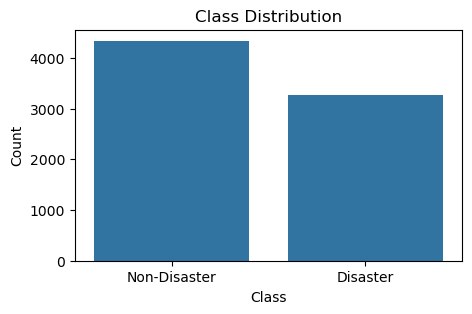


Non-Disaster Tweets: 4342
Disaster Tweets: 3271


In [11]:
#Class Distribution
plt.figure(figsize=(5,3))
sns.countplot(x='target', data=nlp_data)
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks([0,1],['Non-Disaster','Disaster'])
plt.show()
print('\nNon-Disaster Tweets:', nlp_data['target'].value_counts()[0])
print('Disaster Tweets:', nlp_data['target'].value_counts()[1])

In [12]:
#Filter disaster tweet
disaster_tweets=nlp_data[nlp_data['target']==1]['text']
disaster_tweets

0       Our Deeds are the Reason of this #earthquake M...
1                  Forest fire near La Ronge Sask. Canada
2       All residents asked to 'shelter in place' are ...
3       13,000 people receive #wildfires evacuation or...
4       Just got sent this photo from Ruby #Alaska as ...
                              ...                        
7608    Two giant cranes holding a bridge collapse int...
7609    @aria_ahrary @TheTawniest The out of control w...
7610    M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...
7611    Police investigating after an e-bike collided ...
7612    The Latest: More Homes Razed by Northern Calif...
Name: text, Length: 3271, dtype: object

In [13]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\SUKANYA\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\SUKANYA\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [14]:
#Tokenize and count word frequencies
from collections import Counter
from nltk.tokenize import word_tokenize

disaster_tweets = nlp_data[nlp_data['target']==1] ['keyword']
word_freq=Counter()

for tweet in disaster_tweets:
    if pd.notnull(tweet):
        tokens = word_tokenize(tweet.lower())
        word_freq.update(tokens)

#print(disaster_tweets)
print(word_freq)

Counter({'%': 708, 'suicide': 94, '20fires': 72, 'buildings': 52, '20storm': 50, '20disaster': 49, 'mass': 47, 'emergency': 46, 'nuclear': 45, '20fire': 43, 'notavailable': 42, 'forest': 42, 'derailment': 39, 'outbreak': 39, 'wreckage': 39, 'debris': 37, 'oil': 37, '20spill': 37, 'typhoon': 37, 'fire': 33, 'evacuated': 32, 'rescuers': 32, '20bomb': 32, '20bombing': 32, 'burning': 31, 'razed': 31, 'airplane': 30, '20accident': 30, 'earthquake': 30, '20bomber': 30, 'bridge': 29, '20collapse': 29, 'collision': 29, 'wildfire': 29, '20on': 28, 'casualties': 28, 'drought': 28, 'evacuation': 28, '20murder': 28, 'sandstorm': 28, 'bombing': 27, 'devastation': 27, 'hostages': 27, 'sinkhole': 27, 'wild': 27, 'deaths': 26, 'derailed': 26, 'displaced': 26, 'famine': 26, 'fatal': 26, 'fatalities': 26, 'floods': 26, 'thunderstorm': 26, 'violent': 26, 'wounded': 26, 'attack': 25, 'evacuate': 25, 'flooding': 25, 'heat': 25, '20wave': 25, 'massacre': 25, 'accident': 24, '20burning': 24, 'dust': 24, 'hai

In [15]:
#Frequency of phrases
import re

# Function to preprocess text and extract phrases
def extract_phrases(text, n=3):
    text = re.sub(r'[^\w\s]', '', text.lower())  # Remove punctuation and convert to lowercase
    words = text.split()
    phrases = [' '.join(words[i:i+n]) for i in range(len(words)-n+1)]
    return phrases

# Apply the function to the disaster tweets
disaster_tweets['phrases'] = nlp_data['text'].apply(extract_phrases)

# Flatten the list of phrases
all_phrases = [phrase for sublist in disaster_tweets['phrases'] for phrase in sublist]

# Count the frequency of each phrase
phrase_freq = Counter(all_phrases)

# Get the top 20 phrases
top_phrases = phrase_freq.most_common(20)

top_phrases

C:\Users\SUKANYA\AppData\Local\Temp\ipykernel_12672\4104391205.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  disaster_tweets['phrases'] = nlp_data['text'].apply(extract_phrases)


[('i liked a', 42),
 ('liked a youtube', 42),
 ('a youtube video', 42),
 ('northern california wildfire', 29),
 ('more homes razed', 29),
 ('homes razed by', 29),
 ('the latest more', 28),
 ('latest more homes', 28),
 ('razed by northern', 28),
 ('pkk suicide bomber', 28),
 ('suicide bomber who', 28),
 ('bomber who detonated', 28),
 ('who detonated bomb', 28),
 ('detonated bomb in', 28),
 ('by northern california', 27),
 ('16yr old pkk', 27),
 ('old pkk suicide', 27),
 ('families to sue', 26),
 ('to sue over', 26),
 ('sue over legionnaires', 26)]

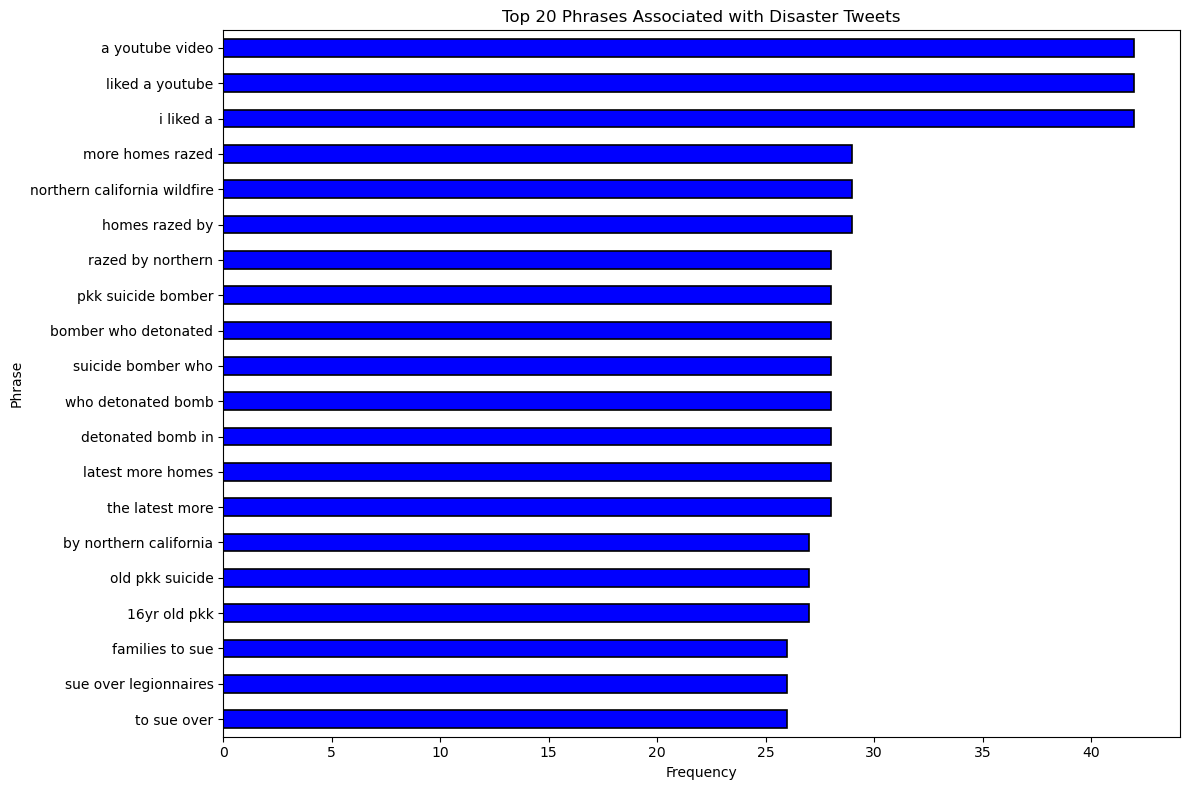

In [16]:
#Plot the top 20 phrases
plt.figure(figsize=(12, 8))
pd.Series(dict(top_phrases)).sort_values().plot(kind='barh', color='blue', edgecolor='black', linewidth=1.2)
plt.title('Top 20 Phrases Associated with Disaster Tweets')
plt.xlabel('Frequency')
plt.ylabel('Phrase')
plt.tight_layout()
plt.show()

In [17]:
#Find Special Characters in dataset
def find_special_characters(text):
    special_characters = re.findall(r'[^a-zA-Z0-9\s]', text)
    return special_characters

nlp_data['special_characters']=nlp_data['text'].apply(find_special_characters)

#Display rows with special characters
special_character_rows=nlp_data[nlp_data['special_characters'].apply(len)>0]
special_character_rows

,id,keyword,location,text,target,special_characters
0,1,NotAvailable,Unknown,Our Deeds are the Reason of this #earthquake M...,1,[#]
1,4,NotAvailable,Unknown,Forest fire near La Ronge Sask. Canada,1,[.]
2,5,NotAvailable,Unknown,All residents asked to 'shelter in place' are ...,1,"[', ', .]"
3,6,NotAvailable,Unknown,"13,000 people receive #wildfires evacuation or...",1,"[,, #]"
4,7,NotAvailable,Unknown,Just got sent this photo from Ruby #Alaska as ...,1,"[#, #]"
...,...,...,...,...,...,...
7608,10869,NotAvailable,Unknown,Two giant cranes holding a bridge collapse int...,1,"[:, /, /, ., /]"
7609,10870,NotAvailable,Unknown,@aria_ahrary @TheTawniest The out of control w...,1,"[@, _, @, ., .]"
7610,10871,NotAvailable,Unknown,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1,"[., [, :, ], ?, ., :, /, /, ., /]"
7611,10872,NotAvailable,Unknown,Police investigating after an e-bike collided ...,1,"[-, ., -, -, .]"


In [18]:
#Clean the text data by removing special chars
import re

Unique_special_characters = {'ü', '£', 'Ó', '!', '>', '`', '^', '\x9d', '}', '[', ';', ':', 'ª', 'Ï', '¬', '|', '~', '*', ',', 'ã', '¢', '\\', '+', '¨', 'å', '¤', "'", '', 'Ò', '/', 'Û', '©', 'Ç', '¡', '#', '«', ')', 'Ê', 'Â', '_', ']', '÷', 'â', '\x89', '@', '$', '?', '&', 'Ñ', '(', '{', '.', '-', '=', '%', '¼', 'Ì', 'È'}

def clean_text(text):
    text = re.sub(r'http\S+|www.\S+', '', text)
    text = re.sub(r'[{}]'.format(''.join(re.escape(c) for c in Unique_special_characters)), ' ', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = text.lower()
    return text

nlp_data['clean_text'] = nlp_data['text'].apply(clean_text)

In [19]:
# Escape special characters so regex treats them literally
escaped_chars = re.escape(''.join(Unique_special_characters))

pattern = r'[{}]'.format(escaped_chars)

# Apply to DataFrame
special_character_rows = nlp_data[nlp_data['clean_text'].str.contains(pattern, regex=True)]
print(special_character_rows)

Empty DataFrame
Columns: [id, keyword, location, text, target, special_characters, clean_text]
Index: []


In [20]:
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\SUKANYA\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\SUKANYA\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [21]:
#Tokenize the text
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

nlp_data['tokens']= nlp_data['clean_text'].apply(word_tokenize)

#Remove stop words
stop_words = set(stopwords.words('english'))
nlp_data['tokens']=nlp_data['tokens'].apply(lambda tokens: [word for word in tokens if word.lower() not in stop_words])
print(stop_words)

#Lemmatization is the process of reducing words to their base or dictionary form (lemma). Unlike stemming, which just chops off endings, lemmatization uses linguistic knowledge (via WordNet in NLTK or spaCy) to ensure the word is valid.
lemmatizer = WordNetLemmatizer()
nlp_data['lemmatized_tokens']=nlp_data['tokens'].apply(lambda x: [lemmatizer.lemmatize(word) for word in x])
print(lemmatizer)
print('\n')
nlp_data.head()


{"she'll", "we'll", 'before', 'between', 'over', 'so', 'did', 'because', 'these', 'through', "it'd", 'won', "weren't", 'in', 'yourself', 'out', 'shan', 'doesn', 'down', 'such', 'mightn', 'them', 'below', 'being', 'myself', 'very', 'off', "mustn't", "they've", 'couldn', "he'll", "couldn't", 'by', 're', "don't", 'about', 'who', "they'll", "he's", 'there', "you've", 'ours', 'hadn', 'you', 'until', 'himself', 'why', 'any', 'which', 'she', 'now', 'just', 'again', "i'm", 'are', 'only', 'were', 'be', 'her', 'itself', 'haven', 'other', 'have', 'is', "she'd", "isn't", 'y', 'where', 'up', "we'd", 've', 'once', 'at', 't', "didn't", 'to', 'ourselves', "it'll", 'that', 'above', 'aren', 'more', 'didn', 's', "won't", 'can', "needn't", 'same', 'while', 'ain', 'will', 'd', 'a', 'him', 'most', 'not', "wouldn't", 'been', "mightn't", 'no', 'too', "you'd", 'own', 'do', 'under', 'does', "i've", 'doing', 'his', 'their', "you're", "they're", 'mustn', "shouldn't", 'whom', 'nor', 'wouldn', 'me', 'o', 'those', '

,id,keyword,location,text,target,special_characters,clean_text,tokens,lemmatized_tokens
0,1,NotAvailable,Unknown,Our Deeds are the Reason of this #earthquake M...,1,[#],our deeds are the reason of this earthquake m...,"[deeds, reason, earthquake, may, allah, forgiv...","[deed, reason, earthquake, may, allah, forgive..."
1,4,NotAvailable,Unknown,Forest fire near La Ronge Sask. Canada,1,[.],forest fire near la ronge sask canada,"[forest, fire, near, la, ronge, sask, canada]","[forest, fire, near, la, ronge, sask, canada]"
2,5,NotAvailable,Unknown,All residents asked to 'shelter in place' are ...,1,"[', ', .]",all residents asked to shelter in place are ...,"[residents, asked, shelter, place, notified, o...","[resident, asked, shelter, place, notified, of..."
3,6,NotAvailable,Unknown,"13,000 people receive #wildfires evacuation or...",1,"[,, #]",13 000 people receive wildfires evacuation or...,"[13, 000, people, receive, wildfires, evacuati...","[13, 000, people, receive, wildfire, evacuatio..."
4,7,NotAvailable,Unknown,Just got sent this photo from Ruby #Alaska as ...,1,"[#, #]",just got sent this photo from ruby alaska as ...,"[got, sent, photo, ruby, alaska, smoke, wildfi...","[got, sent, photo, ruby, alaska, smoke, wildfi..."


####Training & Testing the model

In [22]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(nlp_data['lemmatized_tokens'].apply(lambda x: ' '.join(x)))

# Target variable
y = nlp_data['target']

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
print('\nTraining set shape:', X_train.shape, y_train.shape)
print('\nTesting set shape:', X_test.shape, y_test.shape)


Training set shape: (6090, 15557) (6090,)

Testing set shape: (1523, 15557) (1523,)


##Part 2: Feature Engineering and Model Selection

###EDA

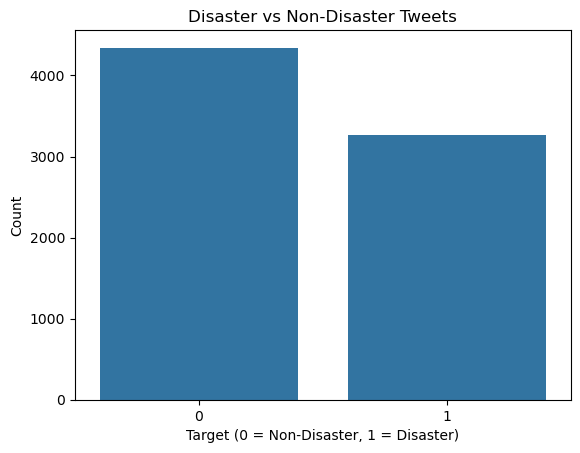

In [25]:
#Class Distribution (Target)
sns.countplot(data=nlp_data, x='target')
plt.title("Disaster vs Non-Disaster Tweets")
plt.xlabel("Target (0 = Non-Disaster, 1 = Disaster)")
plt.ylabel("Count")
plt.show()

####Keyword Frequencies (Top 20 in Disaster Tweets)

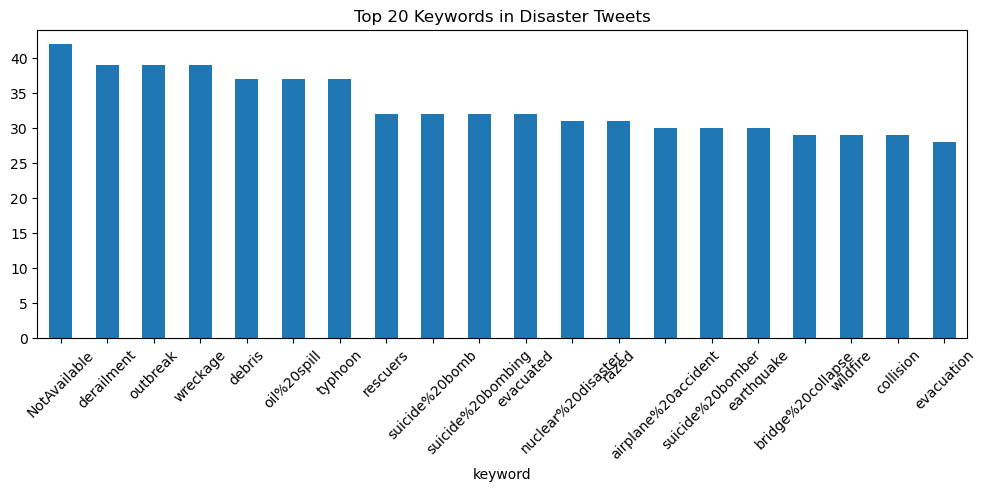

In [26]:
#barchart
top_keywords = nlp_data[nlp_data['target'] == 1]['keyword'].value_counts().head(20)
top_keywords.plot(kind='bar', figsize=(12, 4), title="Top 20 Keywords in Disaster Tweets")
plt.xticks(rotation=45)
plt.show()

####Tweet Length Distribution

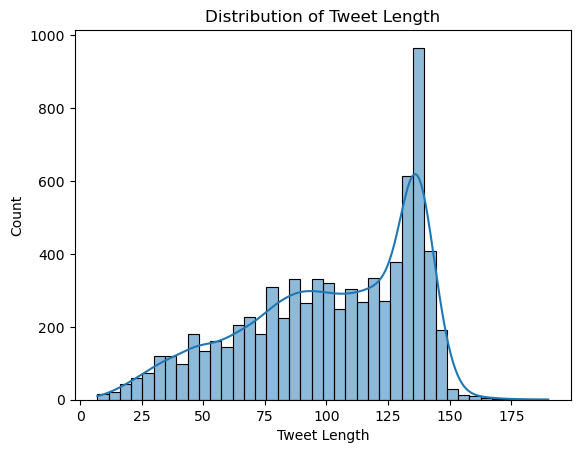

In [27]:
# histplot
nlp_data['text_length'] = nlp_data['text'].apply(len)
sns.histplot(nlp_data['text_length'], kde=True, bins=40)
plt.title("Distribution of Tweet Length")
plt.xlabel("Tweet Length")
plt.ylabel("Count")
plt.show()

####Top 20 Locations

In [28]:
nlp_data['location'].unique()

array(['Unknown', 'Birmingham', 'Est. September 2012 - Bristol', ...,
       '#NewcastleuponTyne #UK', 'Vancouver, Canada', 'Lincoln'],
      dtype=object)

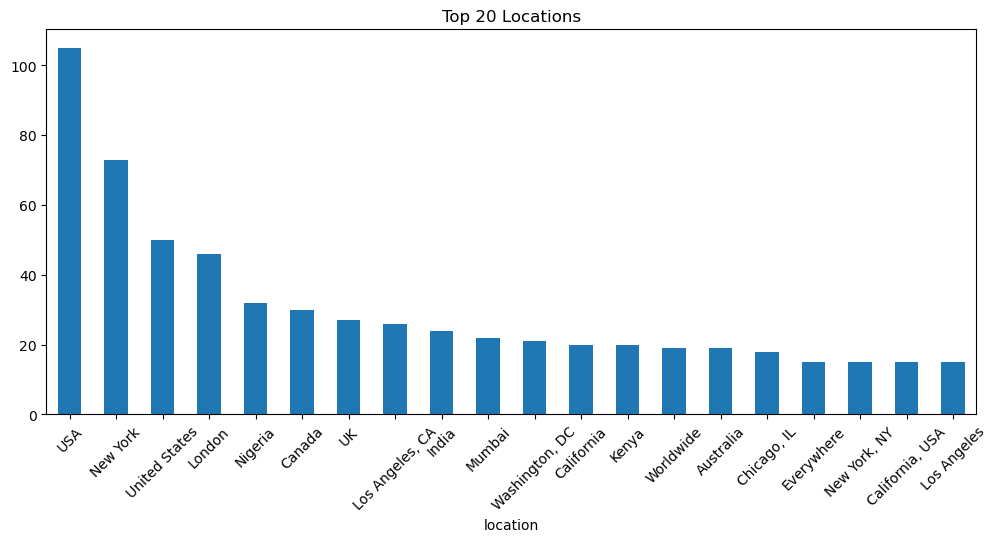

In [29]:
# bar_plot
nlp_data['location'].value_counts().drop('Unknown').head(20).plot(kind='bar', figsize=(12, 5), title="Top 20 Locations")
plt.xticks(rotation=45)
plt.show()

####Distribution of Target (Disaster vs Non-Disaster) % wise

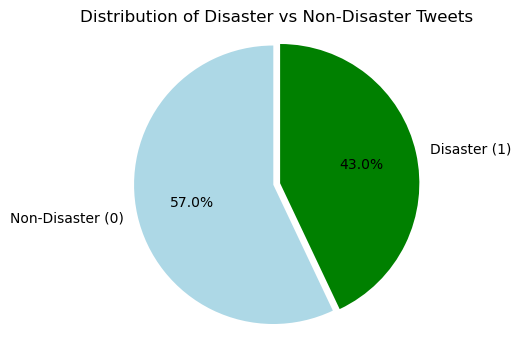

In [30]:
# Pie chart for target distribution
labels = ['Non-Disaster (0)', 'Disaster (1)']
sizes = nlp_data['target'].value_counts().sort_index()
colors = ['lightblue', 'green']

plt.figure(figsize=(4,4))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=90, explode=(0, 0.05))
plt.title("Distribution of Disaster vs Non-Disaster Tweets")
plt.axis('equal')
plt.show()

####Tweet Length by Target Class

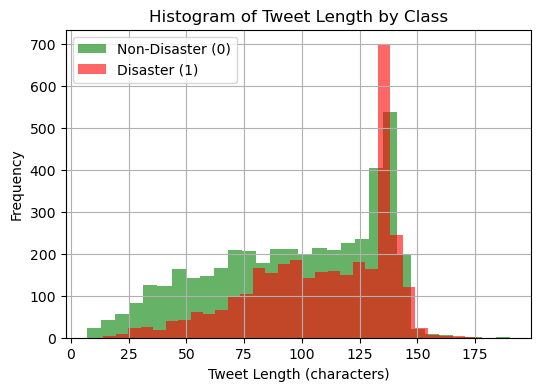

In [31]:
# Add tweet length column
nlp_data['text_len'] = nlp_data['text'].apply(len)

# Histogram
plt.figure(figsize=(6,4))
nlp_data[nlp_data['target']==0]['text_len'].hist(alpha=0.6, bins=30, label='Non-Disaster (0)', color='green')
nlp_data[nlp_data['target']==1]['text_len'].hist(alpha=0.6, bins=30, label='Disaster (1)', color='red')
plt.xlabel("Tweet Length (characters)")
plt.ylabel("Frequency")
plt.title("Histogram of Tweet Length by Class")
plt.legend()
plt.show()

####Word Count by Target Class

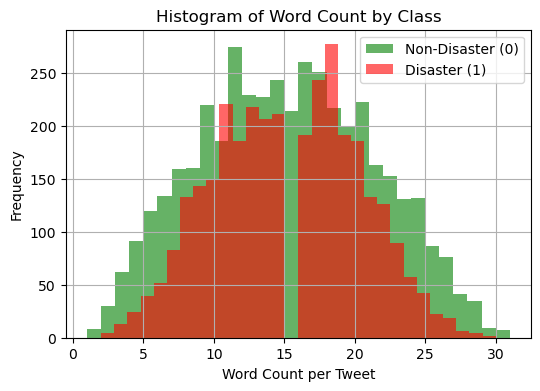

In [32]:
# Word count
nlp_data['word_count'] = nlp_data['text'].apply(lambda x: len(x.split()))

# Histogram
plt.figure(figsize=(6,4))
nlp_data[nlp_data['target']==0]['word_count'].hist(alpha=0.6, bins=30, label='Non-Disaster (0)', color='green')
nlp_data[nlp_data['target']==1]['word_count'].hist(alpha=0.6, bins=30, label='Disaster (1)', color='red')
plt.xlabel("Word Count per Tweet")
plt.ylabel("Frequency")
plt.title("Histogram of Word Count by Class")
plt.legend()
plt.show()

####Correlation of Numeric Features

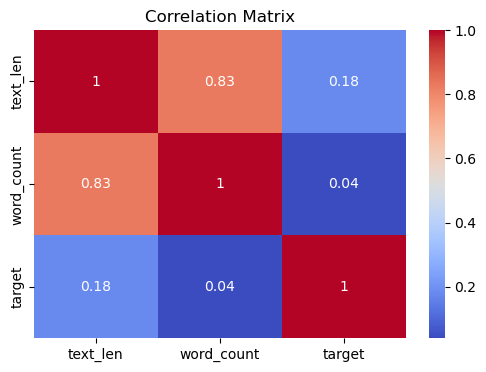

In [33]:
# Correlation plot (only on numeric features)
# Heat_plot
plt.figure(figsize=(6,4))
sns.heatmap(nlp_data[['text_len', 'word_count', 'target']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

####Distribution of Tweet Length

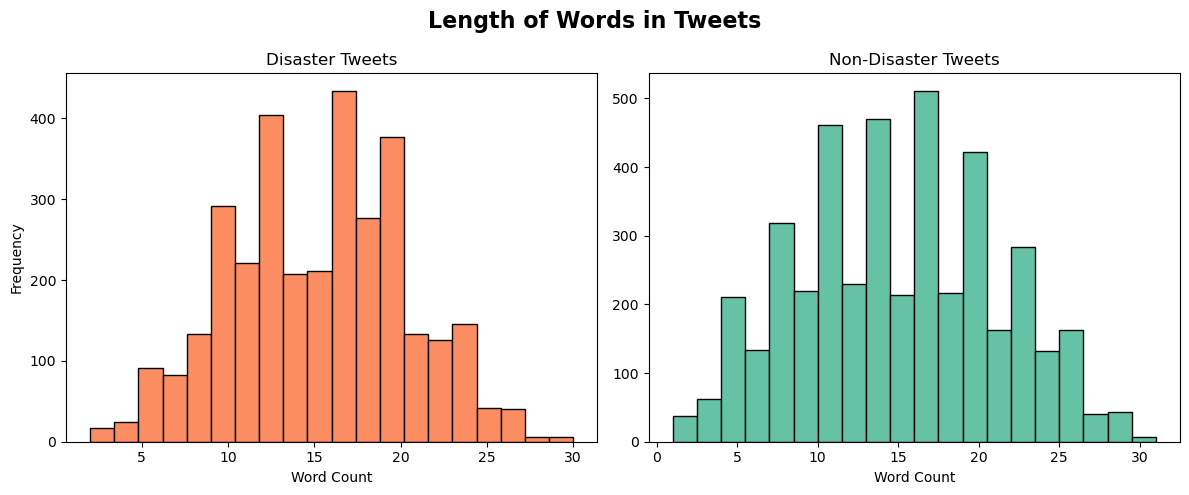

In [34]:
# subplot
word_len_dis = nlp_data[nlp_data['target'] == 1]['text'].str.split().map(len)
word_len_non_dis = nlp_data[nlp_data['target'] == 0]['text'].str.split().map(len)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(word_len_dis, bins=20, color='#fc8d62', edgecolor='black')
plt.title('Disaster Tweets')
plt.xlabel('Word Count')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(word_len_non_dis, bins=20, color='#66c2a5', edgecolor='black')
plt.title('Non-Disaster Tweets')
plt.xlabel('Word Count')
plt.suptitle('Length of Words in Tweets', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

####Average Tweet Length per Class

C:\Users\SUKANYA\AppData\Local\Temp\ipykernel_12672\1136798246.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='target', y='text_len', data=avg_lengths, palette='coolwarm')


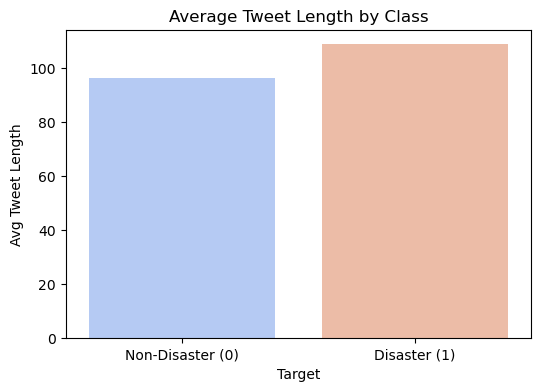

In [35]:
#Bar_plot

avg_lengths = nlp_data.groupby('target')['text_len'].mean().reset_index()

plt.figure(figsize=(6,4))
sns.barplot(x='target', y='text_len', data=avg_lengths, palette='coolwarm')
plt.xticks([0, 1], ['Non-Disaster (0)', 'Disaster (1)'])
plt.title('Average Tweet Length by Class')
plt.ylabel('Avg Tweet Length')
plt.xlabel('Target')
plt.show()

####Text Length vs Word Count

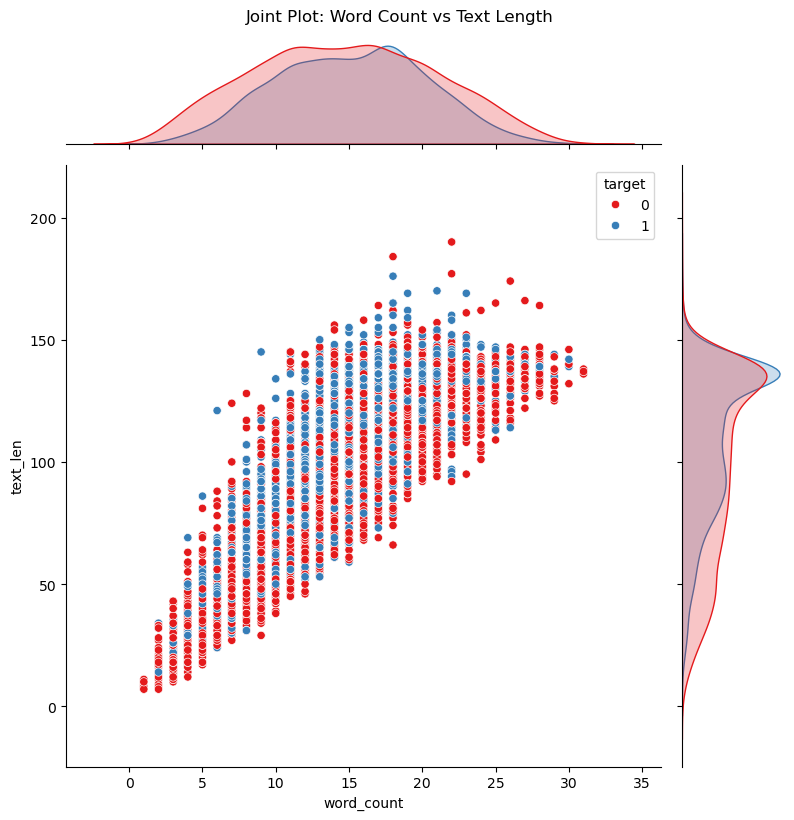

In [36]:
# Joint_Plot
sns.jointplot(data=nlp_data, x='word_count', y='text_len', hue='target', kind='scatter', palette='Set1', height=8)
plt.suptitle('Joint Plot: Word Count vs Text Length', y=1.02)
plt.show()

#####Word Cloud

In [37]:
!pip install wordcloud


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


####Disaster Tweets

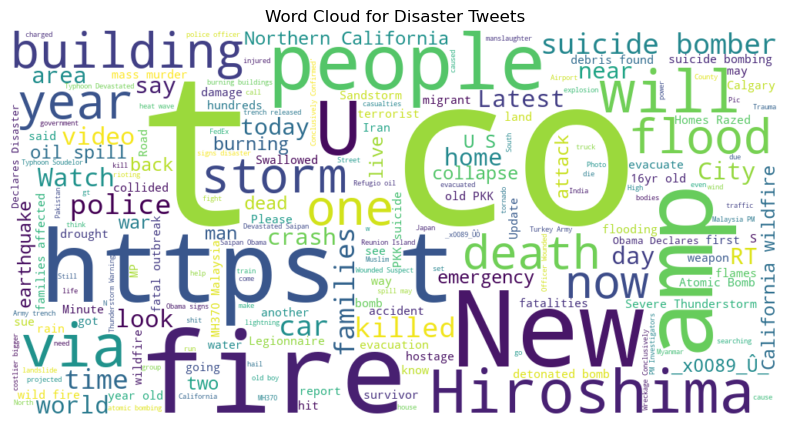

In [38]:
from wordcloud import WordCloud

text_disaster = " ".join(nlp_data[nlp_data['target'] == 1]['text'])
wc = WordCloud(width=1000, height=500, background_color='white').generate(text_disaster)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud for Disaster Tweets")
plt.show()

####Non Disaster tweets

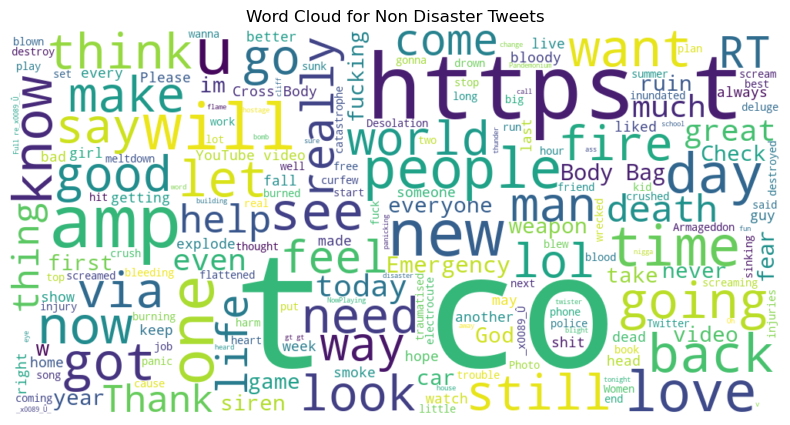

In [39]:
text_Non_disaster = " ".join(nlp_data[nlp_data['target'] == 0]['text'])
wc = WordCloud(width=1000, height=500, background_color='white').generate(text_Non_disaster)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud for Non Disaster Tweets")
plt.show()

####Outliers detection

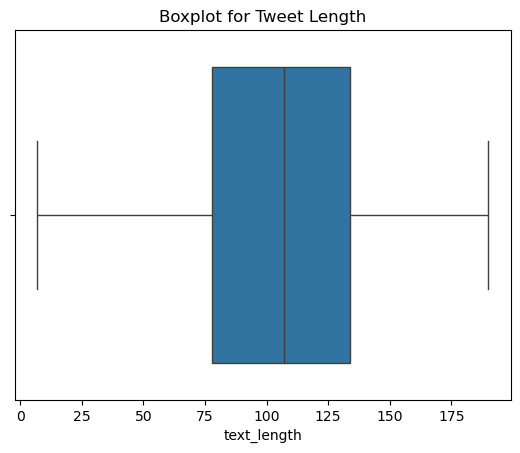

In [40]:
# Boxplot
sns.boxplot(x=nlp_data['text_length'])
plt.title("Boxplot for Tweet Length")
plt.show()

####Text Cleaning & Preprocessing

In [41]:
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Download necessary NLTK data
try:
    nltk.data.find('tokenizers/punkt')
except nltk.downloader.DownloadError:
    nltk.download('punkt')
try:
    nltk.data.find('corpora/stopwords')
except nltk.downloader.DownloadError:
    nltk.download('stopwords')
try:
    nltk.data.find('tokenizers/punkt_tab') # Ensure punkt_tab is downloaded
except nltk.downloader.DownloadError:
    nltk.download('punkt_tab')


stop_words = set(stopwords.words('english'))

In [42]:
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    ...
    tokens = word_tokenize(text)
    cleaned_tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words and len(word) > 2]
    return " ".join(cleaned_tokens)

####Define Cleaning Function

In [43]:
def clean_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", '', text, flags=re.MULTILINE)

    # Remove user mentions and hashtags

    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)  # Remove '#' symbol only, keep the word

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Tokenize
    tokens = word_tokenize(text)

    # Remove stopwords and short tokens
    cleaned_tokens = [word for word in tokens if word not in stop_words and len(word) > 2]

    return " ".join(cleaned_tokens)

####Apply to Dataset

In [44]:
nlp_data['clean_text'] = nlp_data['text'].apply(clean_text)

In [45]:
nlp_filtered = nlp_data.copy()
nlp_filtered['clean_text'] = nlp_filtered['text'].apply(clean_text)

####Vectorize with TF-IDF

In [46]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)  # limit to top 5000 features
X_tfidf = tfidf.fit_transform(nlp_filtered['clean_text'])

In [47]:
nlp_data['has_link'] = nlp_data['text'].apply(lambda x: 1 if 'http' in x else 0)
nlp_data['has_mention'] = nlp_data['text'].apply(lambda x: 1 if '@' in x else 0)
nlp_data['has_hashtag'] = nlp_data['text'].apply(lambda x: 1 if '#' in x else 0)

####Model Building

In [48]:
# import libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

In [49]:
#Vectorize the Cleaned Text
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(nlp_data['clean_text'])

y = nlp_data['target']  # 0: Non-disaster, 1: Disaster

TF-IDF vectorization has transformed the cleaned tweet texts into numerical features, capturing the importance of terms across the dataset.

These features (X) paired with the target labels (y) are now ready for training classification models to predict disaster-related tweets.

####Train/Test Split

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

##Part 3: Model Evaluation and Validation

####Model Evaluation

In [51]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"📌 {name} Performance:")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))
    print("#" * 50)

📌 Logistic Regression Performance:
Accuracy: 0.8030203545633617
Precision: 0.8298676748582231
Recall: 0.6764252696456087
F1 Score: 0.7453310696095077
##################################################
📌 Naive Bayes Performance:
Accuracy: 0.8023637557452397
Precision: 0.8152173913043478
Recall: 0.6933744221879815
F1 Score: 0.7493755203996669
##################################################
📌 Random Forest Performance:
Accuracy: 0.7695338148391333
Precision: 0.7551369863013698
Recall: 0.6795069337442219
F1 Score: 0.7153284671532847
##################################################


####🔹 Key Insights

Logistic Regression:
Highest precision (≈0.83): fewer false positives.
Lower recall (≈0.68): misses some disaster tweets.
Balanced but slightly conservative.

Naive Bayes:
Slightly lower precision but better recall (≈0.69).
Best F1 score (≈0.75): overall balance between precision & recall.
Good choice when recall matters (catching more disaster tweets).

Random Forest:
Lower accuracy and F1 compared to the other two.
Precision and recall are decent but not leading.
May be overfitting or not tuned well.

####Model Validation

In [52]:
pip install joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [53]:
#import libraries

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import joblib

# Example preprocessing & data split
X = nlp_data['clean_text']
y = nlp_data['target']

# TF-IDF vectorization
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(X)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(solver='liblinear'))
])
params = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__max_df': [0.9, 1.0],
    'clf__C': [0.1, 1, 10]
}

# Train model
model = LogisticRegression()
model.fit(X_train, y_train)

# Save model
joblib.dump(model, 'model.pkl')

# Save vectorizer
joblib.dump(tfidf, 'vectorizer.pkl')

['vectorizer.pkl']

In [54]:
nlp_data = nlp_data[['text', 'target']]

In [55]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+|#\w+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    return text.strip()

nlp_data['clean_text'] = nlp_data['text'].apply(clean_text)

####Using Deep learning algorithms

####Train and Save the Tokenizer

In [59]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import pickle

# Step 1: Create and fit tokenizer
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(nlp_data['clean_text'].values)

# Step 2: Convert text to sequences and pad
sequences = tokenizer.texts_to_sequences(nlp_data['clean_text'].values)
padded = pad_sequences(sequences, maxlen=100, padding='post', truncating='post')

# Step 3: Save tokenizer
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

In [57]:
# Load tokenizer when needed
with open("tokenizer.pkl", "rb") as f:
    tokenizer = pickle.load(f)

# Use tokenizer again
new_sequences = tokenizer.texts_to_sequences(["This is a test tweet"])
new_padded = pad_sequences(new_sequences, maxlen=100)

In [58]:
# Save model
joblib.dump(model,"disaster_model.h5")

# Save tokenizer
import pickle
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)